In [1]:
import numpy as np
import pandas as pd

In [2]:
def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


A1, L1 = load_mean_adj(
    './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A2, L2 = load_mean_adj(
    './result/wo_layer/stage2/tuning/bs64_dp0.8_sw0.7/dynamic_full_graphs.npy',
    './result/wo_layer/stage2/df_scaled.csv'
)

A3, L3 = load_mean_adj(
    './result/wo_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage3/df_scaled.csv'
)


## 1. Validation

In [3]:
def classify_pairs(adjA, adjB, labels, nameA="A", nameB="B"):
    n = adjA.shape[0]

    # sign(A) * sign(B) = -1 
    signA = np.sign(adjA)
    signB = np.sign(adjB)

    flip_mask = (signA * signB == -1)

    flip_pairs = []
    for i in range(n):
        for j in range(n):
            if flip_mask[i, j]:
                flip_pairs.append({
                    "source": labels[i],
                    "target": labels[j],
                    f"{nameA}_weight": adjA[i, j],
                    f"{nameB}_weight": adjB[i, j],
                    "difference": adjA[i, j] - adjB[i, j]
                })

    df_flip = pd.DataFrame(flip_pairs)

    same_mask = (signA * signB == 1) & (signA != 0)

    same_pairs = []
    for i in range(n):
        for j in range(n):
            if same_mask[i, j]:
                same_pairs.append({
                    "source": labels[i],
                    "target": labels[j],
                    f"{nameA}_weight": adjA[i, j],
                    f"{nameB}_weight": adjB[i, j],
                    "difference": adjA[i, j] - adjB[i, j]
                })

    df_same = pd.DataFrame(same_pairs)

    return df_flip, df_same

df_12_flip, df_12_same = classify_pairs(A1, A2, L1, nameA="A1", nameB="A2")
df_13_flip, df_13_same = classify_pairs(A1, A3, L1, nameA="A1", nameB="A3")
df_23_flip, df_23_same = classify_pairs(A2, A3, L2, nameA="A2", nameB="A3")

In [5]:
def evaluate_source_plasticity(df_flip, df_same, A1=None, A2=None, labels=None, nameA="A", nameB="B"):
    all_sources = pd.concat([df_flip, df_same])["source"].unique()
    results = []

    # ====== Precompute NCC / WSFR only if adjacency provided ======
    if A1 is not None and A2 is not None and labels is not None:
        label_to_idx = {lab: i for i, lab in enumerate(labels)}

        # Precompute norms & dot products for NCC
        dot = np.sum(A1 * A2, axis=1)
        norm1 = np.linalg.norm(A1, axis=1)
        norm2 = np.linalg.norm(A2, axis=1)
        cos_sim = np.divide(dot, norm1 * norm2, out=np.zeros_like(dot), where=(norm1 * norm2) != 0)
        NCC_all = 1 - cos_sim  # full vector

        # Precompute WSFR
        sign1 = np.sign(A1)
        sign2 = np.sign(A2)
        flip_mask_mat = (sign1 * sign2 == -1)
        delta = np.abs(A1 - A2)

        # numerator, denominator for each source node
        WSFR_num = np.sum(delta * flip_mask_mat, axis=1)
        WSFR_denom = np.sum(np.abs(A1) + np.abs(A2), axis=1)
        WSFR_all = np.divide(WSFR_num, WSFR_denom,
                             out=np.zeros_like(WSFR_num),
                             where=WSFR_denom != 0)
    else:
        NCC_all = None
        WSFR_all = None

    # ================= main loop ==================
    for s in all_sources:

        df_flip_s = df_flip[df_flip["source"] == s]
        df_same_s = df_same[df_same["source"] == s]

        flip_count = len(df_flip_s)
        same_count = len(df_same_s)
        total = flip_count + same_count

        # ---------- NRB ----------
        if flip_count > 0:
            flip_to_exc = (df_flip_s[f"{nameA}_weight"] < 0) & (df_flip_s[f"{nameB}_weight"] > 0)
            flip_to_inh = (df_flip_s[f"{nameA}_weight"] > 0) & (df_flip_s[f"{nameB}_weight"] < 0)
            num_exc = flip_to_exc.sum()
            num_inh = flip_to_inh.sum()
        else:
            num_exc = num_inh = 0

        # ---------- Flip Strength ----------
        if flip_count > 0:
            flip_strength = np.mean(np.abs(df_flip_s[f"{nameA}_weight"] - df_flip_s[f"{nameB}_weight"]))
        else:
            flip_strength = 0

        # ---------- NCC & WSFR ----------
        if NCC_all is not None:
            idx = label_to_idx[s]
            NCC = NCC_all[idx]
            WSFR = WSFR_all[idx]
        else:
            NCC = None
            WSFR = None

        results.append({
            "source": s,
            "flip_count": flip_count,
            "same_count": same_count,
            "total_nonzero": total,
            "SFR": flip_count / total if total > 0 else 0,
            "SSR": same_count / total if total > 0 else 0,
            "NRB": num_exc - num_inh,
            "FlipStrength": flip_strength,
            "WSFR": WSFR,
            "NCC": NCC
        })

    return pd.DataFrame(results).sort_values("SFR", ascending=False)




df_source_12 = evaluate_source_plasticity(
    df_12_flip, df_12_same,
    A1=A1, A2=A2, labels=L1,
    nameA="A1", nameB="A2"
)
df_source_13 = evaluate_source_plasticity(
    df_13_flip, df_13_same,
    A1=A1, A2=A3, labels=L1,
    nameA="A1", nameB="A3"
)
df_source_23 = evaluate_source_plasticity(
    df_23_flip, df_23_same,
    A1=A2, A2=A3, labels=L2,
    nameA="A2", nameB="A3"
)

In [6]:
df_source_12

,source,flip_count,same_count,total_nonzero,SFR,SSR,NRB,FlipStrength,WSFR,NCC
39,AAA,1,0,1,1.000000,0.000000,1,0.173405,1.000000,2.000000e+00
33,PIR,1,0,1,1.000000,0.000000,-1,1.346742,1.000000,2.000000e+00
28,RSPv,10,9,19,0.526316,0.473684,-10,0.689368,0.505174,8.589196e-01
19,ACAd,2,2,4,0.500000,0.500000,2,0.471557,0.414653,7.610419e-01
0,FRP,1,1,2,0.500000,0.500000,1,1.320854,0.517969,9.726491e-01
...,...,...,...,...,...,...,...,...,...,...
62,TR,0,2,2,0.000000,1.000000,0,0.000000,0.000000,1.641477e-07
63,ENTl,0,3,3,0.000000,1.000000,0,0.000000,0.000000,2.408487e-03
72,PVT,0,6,6,0.000000,1.000000,0,0.000000,0.000000,1.358078e-02
73,CM,0,9,9,0.000000,1.000000,0,0.000000,0.000000,2.075792e-02


In [7]:
df_nt = pd.read_csv("../transcriptome/merfish/neurotransmitter_fraction.csv",index_col=0)
df_nt

,Chol,Dopa,GABA,GABA-Glyc,Glut,Glut-GABA,Nora,Sero
AAA,0.026902,0.0,0.736864,0.000420,0.231610,0.004203,0.0,0.0
ACAd,0.000000,0.0,0.118460,0.000000,0.880990,0.000550,0.0,0.0
ACAv,0.000000,0.0,0.091720,0.000000,0.907890,0.000390,0.0,0.0
ACB,0.007831,0.0,0.986176,0.000000,0.004522,0.001471,0.0,0.0
AId,0.000000,0.0,0.132951,0.000000,0.866645,0.000404,0.0,0.0
...,...,...,...,...,...,...,...,...
VM,0.000000,0.0,0.040731,0.000522,0.958747,0.000000,0.0,0.0
VPL,0.000000,0.0,0.055556,0.000000,0.944444,0.000000,0.0,0.0
VPLpc,0.000000,0.0,0.017182,0.000000,0.982818,0.000000,0.0,0.0
VPM,0.000000,0.0,0.005398,0.000000,0.994602,0.000000,0.0,0.0


In [8]:
def calculate_category_proportions(row):
    excitatory_sum = sum([row[col] for col in ["Glut"] if row[col] > 0])
    inhibitory_sum = sum([row[col] for col in ["GABA-Glyc", "GABA"] if row[col] > 0])
    modulatory_sum = sum([row[col] for col in ["Chol", "Dopa", "Nora", "Sero", "Glut-GABA"] if row[col] > 0])

    total = excitatory_sum + inhibitory_sum + modulatory_sum
    if total == 0: 
        return {"Excitatory": 0, "Inhibitory": 0, "Modulatory": 0}
    
    return {
        "Excitatory": excitatory_sum / total,
        "Inhibitory": inhibitory_sum / total,
        "Modulatory": modulatory_sum / total
    }

def calculate_non_dominance_std(row):

    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    
    proportions = [p_exc, p_inh, p_mod]
    return np.std(proportions)

def calculate_non_dominance_max(row):
    p_exc = row["Excitatory"] 
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    return 1 - max(p_exc+p_mod, p_inh+p_mod)

def calculate_dominance_max(row, exc_weight=1, inh_weight=1.1):
    p_exc = row["Excitatory"] * exc_weight  
    p_inh = row["Inhibitory"] * inh_weight  
    p_mod = row["Modulatory"]

    return max(p_exc + p_mod, p_inh + p_mod)


def calculate_Shannon_Entropy(row):
    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]

    p = np.array([p_exc, p_inh, p_mod])
    
    p = p[p > 0]

    return -np.sum(p * np.log(p))


def calculate_gini(row):
    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    
    proportions = [p_exc, p_inh, p_mod]
    gini = 1 - sum(p ** 2 for p in proportions)
    
    return gini

In [9]:
df_merge_12 = df_source_12.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_12_sorted = df_merge_12.sort_values("SFR", ascending=False)
df_source_12_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_12_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_12_sorted["Non_Dominance_Max"] = df_source_12_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_12_sorted["Dominance_Max"] = df_source_12_sorted.apply(calculate_dominance_max, axis=1)
df_source_12_sorted["Shannon_Entropy"] = df_source_12_sorted.apply(calculate_Shannon_Entropy, axis=1)
#df_source_12_sorted["Gini"] = df_source_12_sorted.apply(calculate_gini, axis=1)
df_source_12_sorted[["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Non_Dominance_Max", "Shannon_Entropy", "Dominance_Max"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Non_Dominance_Max,Shannon_Entropy,Dominance_Max
33,PIR,1.000000,0.862519,0.135740,0.001740,0.135740,0.409697,0.864260
39,AAA,1.000000,0.231610,0.737285,0.031106,0.231610,0.671434,0.842119
28,RSPv,0.526316,0.881536,0.118278,0.000186,0.118278,0.365238,0.881722
19,ACAd,0.500000,0.880990,0.118460,0.000550,0.118460,0.368454,0.881540
38,OT,0.500000,0.005604,0.989165,0.005231,0.005604,0.067310,1.093312
...,...,...,...,...,...,...,...,...
69,BST,0.000000,0.094437,0.855962,0.049601,0.094437,0.504970,0.991159
67,ACB,0.000000,0.004522,0.986176,0.009302,0.004522,0.081652,1.094095
72,PVT,0.000000,0.994775,0.005225,0.000000,0.005225,0.032665,0.994775
73,CM,0.000000,1.000000,0.000000,0.000000,0.000000,-0.000000,1.000000


In [12]:
df_merge_13 = df_source_13.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_13_sorted = df_merge_13.sort_values("SFR", ascending=False)
df_source_13_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_13_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_13_sorted["Non_Dominance_Max"] = df_source_13_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_13_sorted["Shannon_Entropy"] = df_source_13_sorted.apply(calculate_Shannon_Entropy, axis=1)
df_source_13_sorted["Dominance_Max"] = df_source_13_sorted.apply(calculate_dominance_max, axis=1)
df_source_13_sorted[["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Non_Dominance_Max", "Shannon_Entropy", "Dominance_Max"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Non_Dominance_Max,Shannon_Entropy,Dominance_Max
32,PIR,1.000000,0.862519,0.135740,0.001740,0.135740,0.409697,0.864260
38,AAA,1.000000,0.231610,0.737285,0.031106,0.231610,0.671434,0.842119
27,RSPv,0.578947,0.881536,0.118278,0.000186,0.118278,0.365238,0.881722
21,ORBl,0.500000,0.855295,0.144187,0.000517,0.144187,0.416844,0.855813
37,OT,0.500000,0.005604,0.989165,0.005231,0.005604,0.067310,1.093312
...,...,...,...,...,...,...,...,...
66,BLA,0.000000,0.749210,0.249097,0.001692,0.249097,0.573346,0.750903
70,SGN,0.000000,0.995842,0.004158,0.000000,0.004158,0.026947,0.995842
72,PVT,0.000000,0.994775,0.005225,0.000000,0.005225,0.032665,0.994775
73,CM,0.000000,1.000000,0.000000,0.000000,0.000000,-0.000000,1.000000


In [13]:
df_merge_23 = df_source_23.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_23_sorted = df_merge_23.sort_values("SFR", ascending=False)
df_source_23_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_23_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_23_sorted["Non_Dominance_Max"] = df_source_23_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_23_sorted["Shannon_Entropy"] = df_source_23_sorted.apply(calculate_Shannon_Entropy, axis=1)
df_source_23_sorted["Dominance_Max"] = df_source_23_sorted.apply(calculate_dominance_max, axis=1)

#df_source_23_sorted["Balance_Exc_Inh"] = 1 - abs(df_source_23_sorted["Excitatory"] - df_source_23_sorted["Inhibitory"])
#df_source_23_sorted["Plasticity_Score"] = df_source_23_sorted["Balance_Exc_Inh"] * df_source_23_sorted["Modulatory"]

df_source_23_sorted[df_source_23_sorted['SFR']>0][["source", "SFR",  "Excitatory", "Inhibitory", "Modulatory", "Non_Dominance_Max", "Shannon_Entropy", "Dominance_Max"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Non_Dominance_Max,Shannon_Entropy,Dominance_Max
4,ORBl,0.250000,0.855295,0.144187,0.000517,0.144187,0.416844,0.855813
17,PO,0.133333,0.996929,0.003071,0.000000,0.003071,0.020833,0.996929
5,RSPagl,0.125000,0.881339,0.117931,0.000731,0.117931,0.368697,0.882069
10,VAL,0.125000,0.951062,0.048938,0.000000,0.048938,0.195375,0.951062
3,VISal,0.111111,0.879718,0.119929,0.000353,0.119929,0.369896,0.880071
15,VPMpc,0.100000,0.976532,0.023468,0.000000,0.023468,0.111245,0.976532
13,VPLpc,0.076923,0.982818,0.017182,0.000000,0.017182,0.086860,0.982818
14,VPM,0.068966,0.994602,0.005398,0.000000,0.005398,0.033571,0.994602
1,MOs,0.064516,0.851528,0.147406,0.001066,0.147406,0.426376,0.852594
6,RSPd,0.062500,0.879433,0.119915,0.000652,0.119915,0.372105,0.880085


In [14]:
df_combined = pd.concat([df_source_12_sorted, df_source_13_sorted, df_source_23_sorted], axis=0, ignore_index=True)
df_combined = df_combined[df_combined['SFR']>0]
df_combined = df_combined[df_combined['FlipStrength']>0]
df_combined = df_combined[df_combined['total_nonzero']>0]
df_combined = df_combined.loc[
    df_combined.groupby("source")["WSFR"].idxmax()
].reset_index(drop=True)

df_combined 

,source,flip_count,same_count,total_nonzero,SFR,SSR,NRB,FlipStrength,WSFR,NCC,...,Glut,Glut-GABA,Nora,Sero,Excitatory,Inhibitory,Modulatory,Non_Dominance_Max,Dominance_Max,Shannon_Entropy
0,AAA,1,0,1,1.000000,0.000000,1,0.173405,1.000000,2.000000,...,0.231610,0.004203,0.000000,0.000000,0.231610,0.737285,0.031106,0.231610,0.842119,0.671434
1,ACAd,2,2,4,0.500000,0.500000,2,0.478505,0.423173,0.803298,...,0.880990,0.000550,0.000000,0.000000,0.880990,0.118460,0.000550,0.118460,0.881540,0.368454
2,ACAv,1,7,8,0.125000,0.875000,-1,0.529405,0.071040,0.055107,...,0.907890,0.000390,0.000000,0.000000,0.907890,0.091720,0.000390,0.091720,0.908280,0.309913
3,AId,2,19,21,0.095238,0.904762,2,0.490649,0.077071,0.130659,...,0.866645,0.000404,0.000000,0.000000,0.866645,0.132951,0.000404,0.132951,0.867049,0.395459
4,AIp,1,7,8,0.125000,0.875000,1,0.338022,0.066187,0.057448,...,0.843035,0.001554,0.000000,0.000000,0.843035,0.155270,0.001695,0.155270,0.844730,0.443966
5,AIv,1,5,6,0.166667,0.833333,1,1.124084,0.248740,0.445809,...,0.891697,0.000963,0.000000,0.000000,0.891697,0.107100,0.001203,0.107100,0.892900,0.349565
6,AUDp,1,9,10,0.100000,0.900000,-1,0.239584,0.031940,0.014889,...,0.870843,0.000827,0.000000,0.000000,0.870843,0.128330,0.000827,0.128330,0.871670,0.389781
7,AUDv,9,12,21,0.428571,0.571429,7,0.502095,0.463741,1.229109,...,0.854861,0.000731,0.000000,0.000000,0.854861,0.144408,0.000731,0.144408,0.855592,0.418781
8,CA1,1,2,3,0.333333,0.666667,1,1.888829,0.322908,0.624937,...,0.852943,0.004312,0.000000,0.000000,0.852943,0.142745,0.004312,0.142745,0.857255,0.437038
9,CLA,7,26,33,0.212121,0.787879,5,0.673226,0.246345,0.609955,...,0.902860,0.001079,0.000000,0.000000,0.902860,0.096060,0.001079,0.096060,0.903940,0.324683


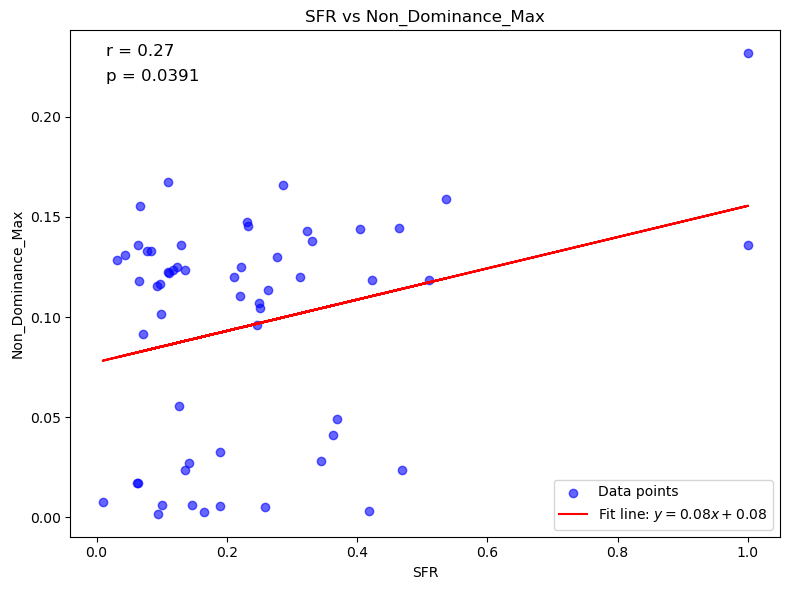

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats


corr, p_value = stats.pearsonr(df_combined["WSFR"], df_combined["Non_Dominance_Max"])

plt.figure(figsize=(8, 6))
plt.scatter(df_combined["WSFR"], df_combined["Non_Dominance_Max"], color='blue', label="Data points", alpha=0.6)

slope, intercept = np.polyfit(df_combined["WSFR"], df_combined["Non_Dominance_Max"], 1)
plt.plot(df_combined["WSFR"], slope * df_combined["WSFR"] + intercept, color='red', label=f"Fit line: $y = {slope:.2f}x + {intercept:.2f}$")

plt.title("SFR vs Non_Dominance_Max")
plt.xlabel("SFR")
plt.ylabel("Non_Dominance_Max")

plt.text(0.05, 0.95, f"r = {corr:.2f}", transform=plt.gca().transAxes, fontsize=12)
plt.text(0.05, 0.90, f"p = {p_value:.4f}", transform=plt.gca().transAxes, fontsize=12)

plt.legend()
plt.tight_layout()
plt.show()

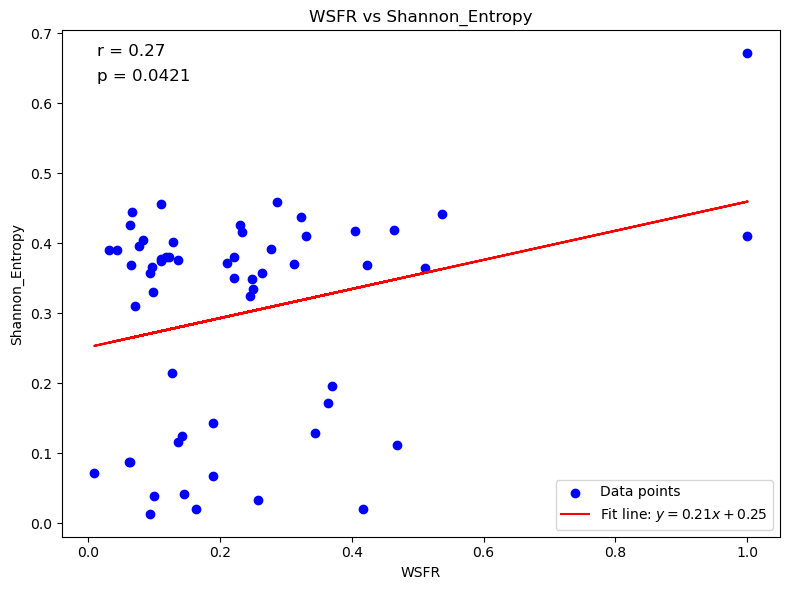

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats


corr, p_value = stats.pearsonr(df_combined["WSFR"], df_combined["Shannon_Entropy"])

plt.figure(figsize=(8, 6))
plt.scatter(df_combined["WSFR"], df_combined["Shannon_Entropy"], color='blue', label="Data points", alpha=1)

slope, intercept = np.polyfit(df_combined["WSFR"], df_combined["Shannon_Entropy"], 1)
plt.plot(df_combined["WSFR"], slope * df_combined["WSFR"] + intercept, color='red', label=f"Fit line: $y = {slope:.2f}x + {intercept:.2f}$")

plt.title("WSFR vs Shannon_Entropy")
plt.xlabel("WSFR")
plt.ylabel("Shannon_Entropy")

plt.text(0.05, 0.95, f"r = {corr:.2f}", transform=plt.gca().transAxes, fontsize=12)
plt.text(0.05, 0.90, f"p = {p_value:.4f}", transform=plt.gca().transAxes, fontsize=12)

plt.legend()
plt.tight_layout()
plt.savefig("WSFR_vs_Shannon_Entropy.pdf", format='pdf', bbox_inches='tight', transparent=True)
plt.show()

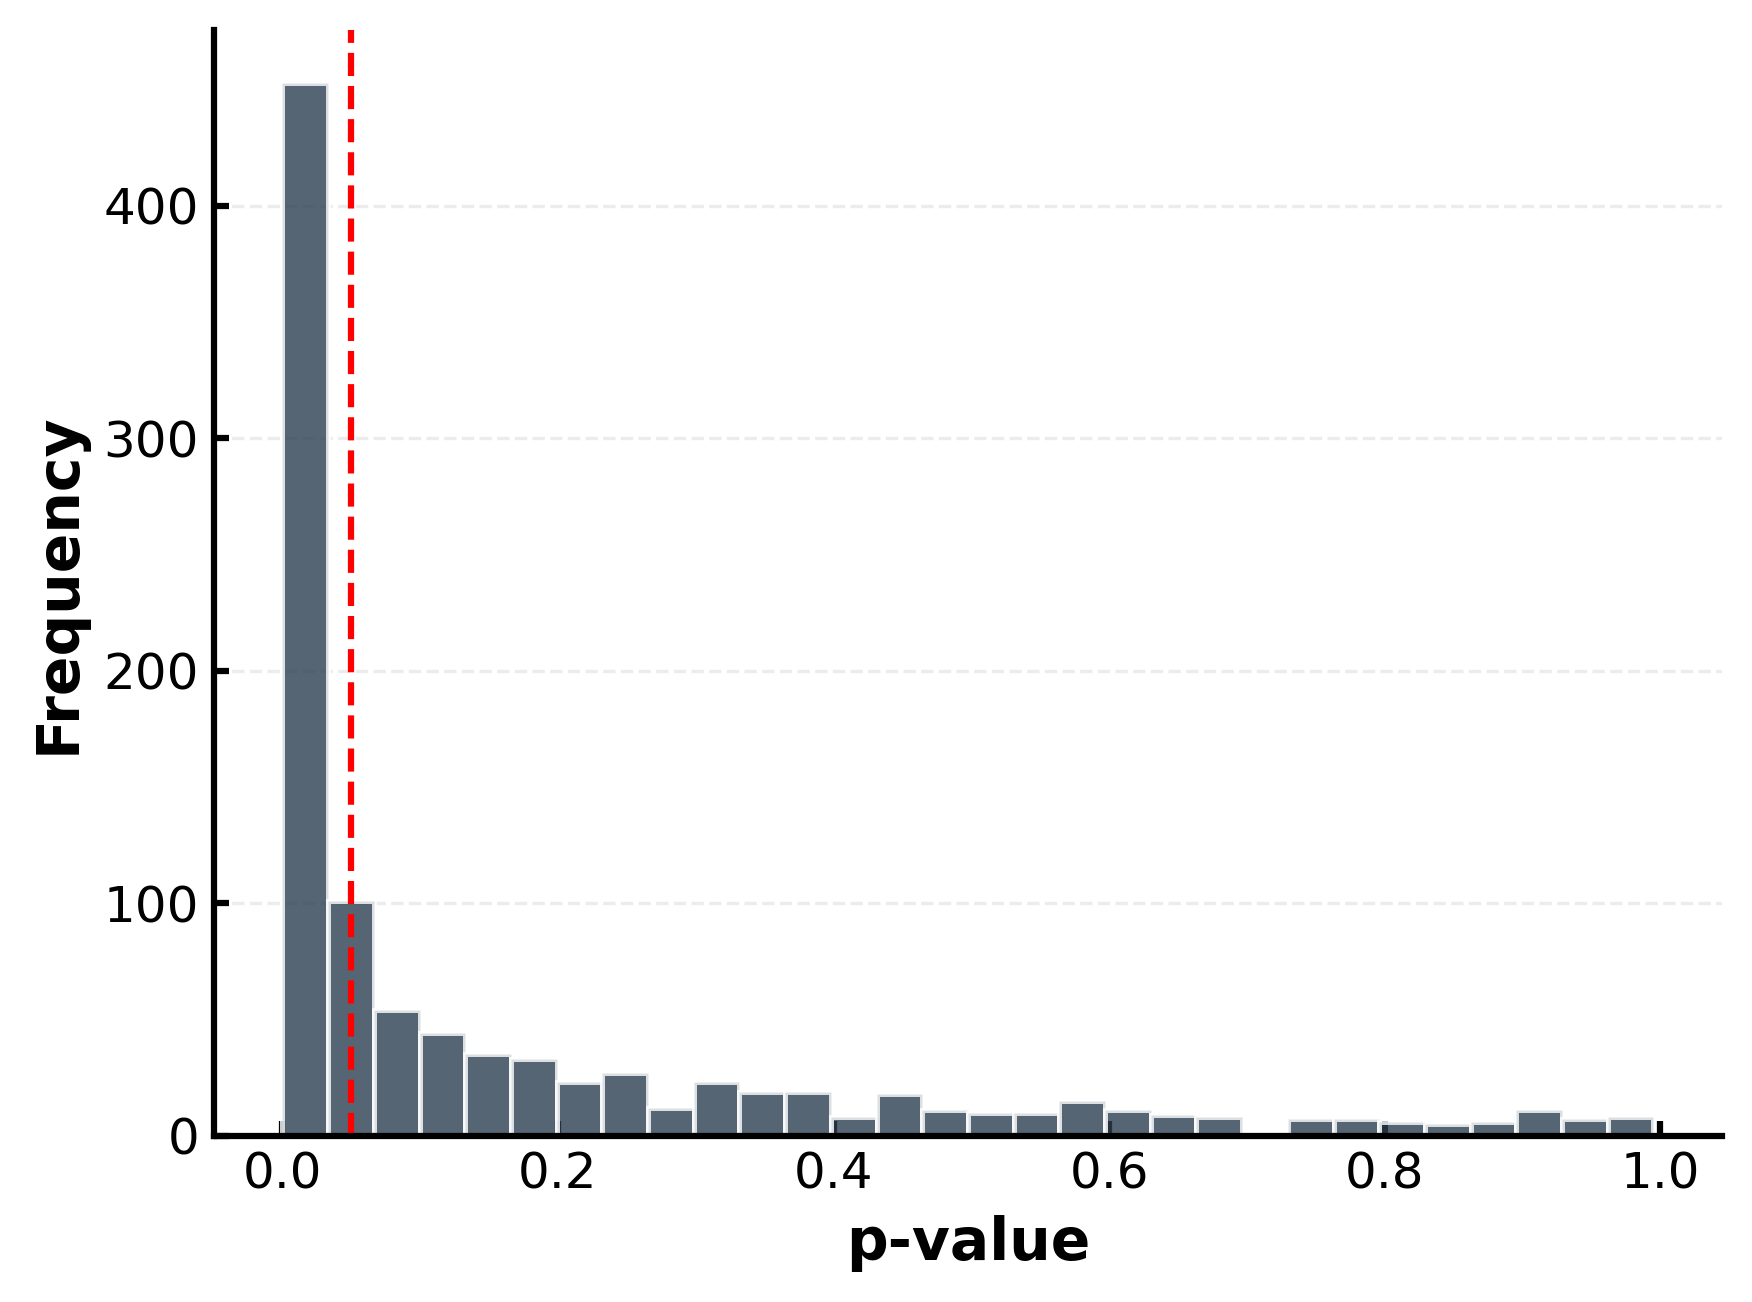

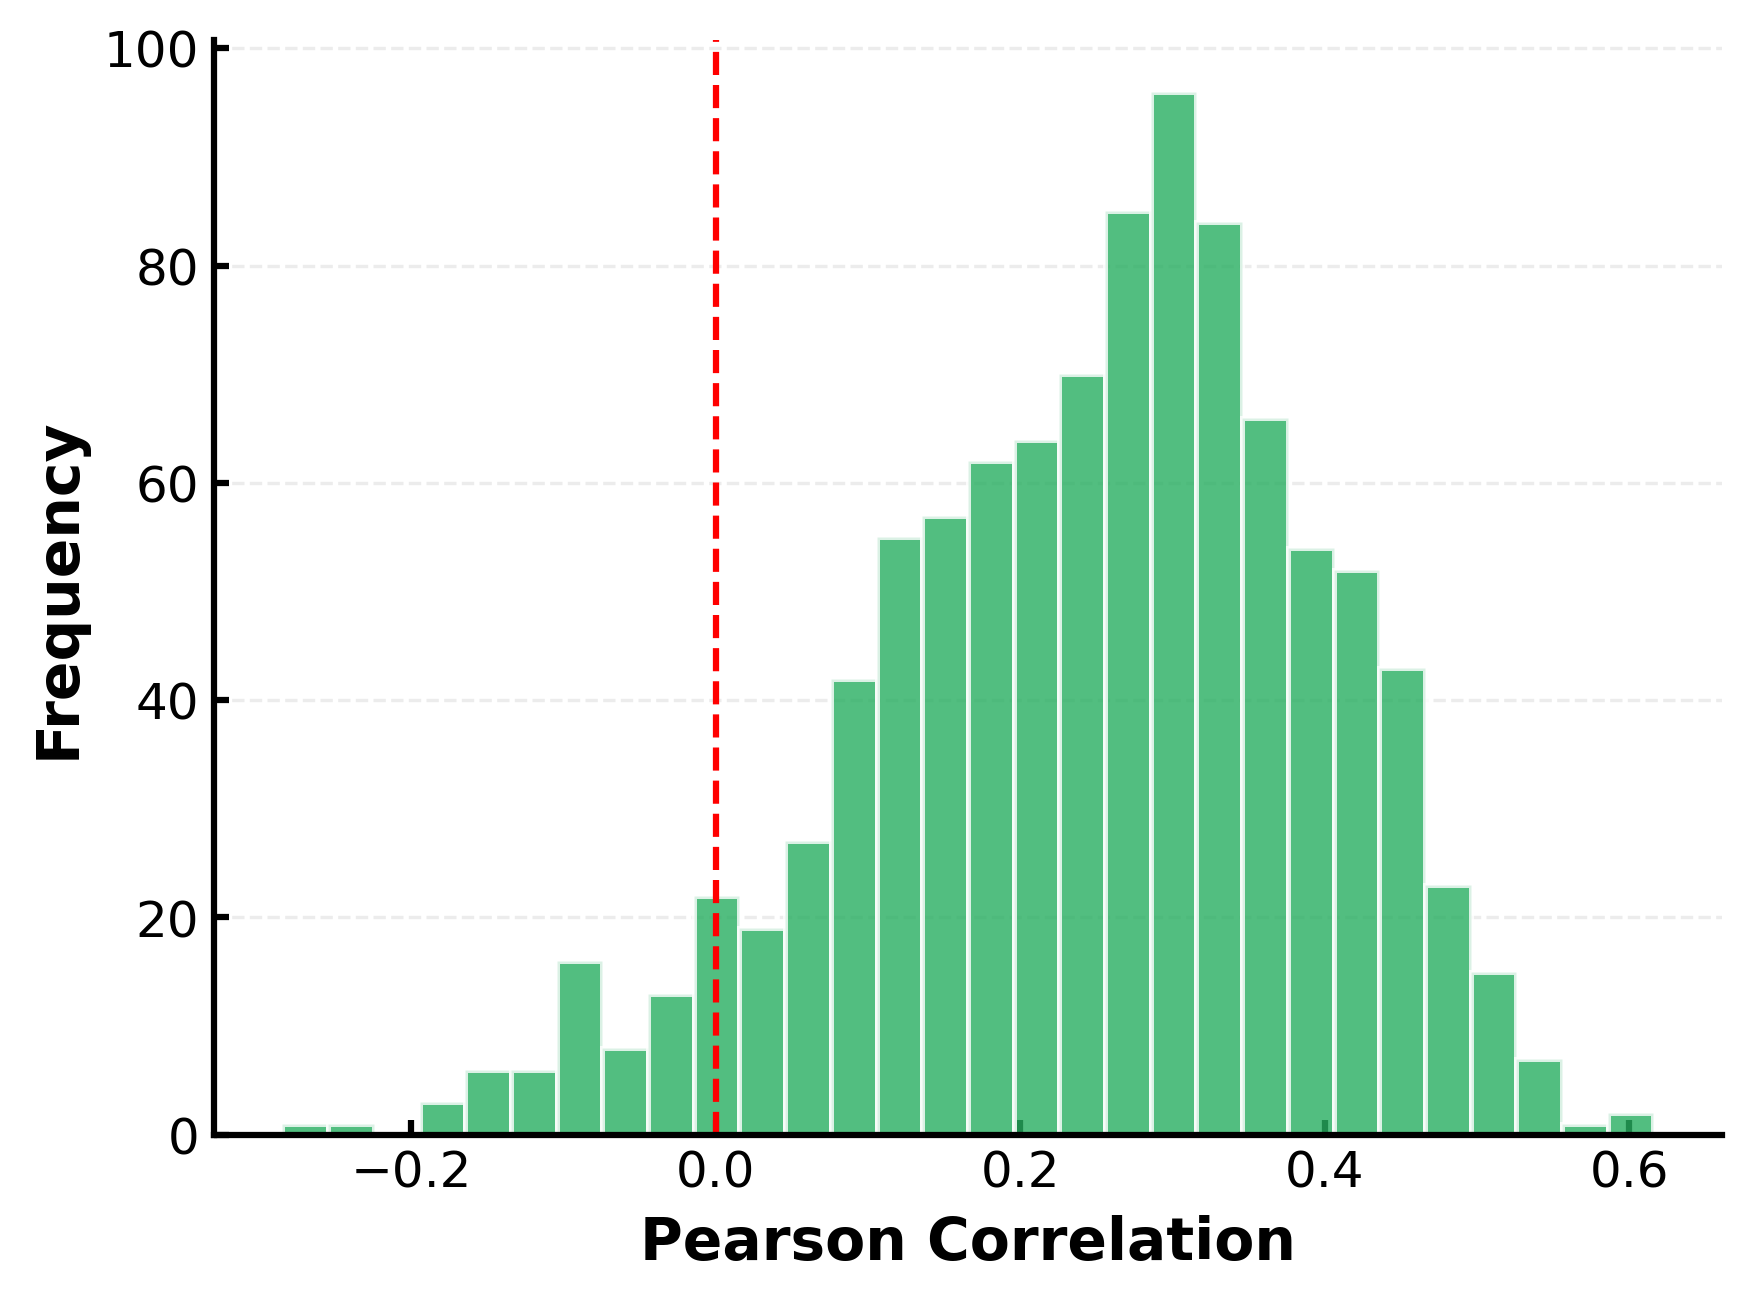

Proportion of p-values <= 0.05: 51.3%
Proportion of correlations > 0: 93.8%

Correlation: Mean = 0.248, 95% CI = [-0.084, 0.494]
Slope: Mean = 0.189, 95% CI = [-0.087, 0.374]
P-value: Mean = 0.1692


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

RANDOM_SEED = 123
np.random.seed(RANDOM_SEED)

plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

COLOR_PRIMARY = '#2C3E50'
COLOR_ACCENT = '#27AE60'
COLOR_GRID = '#E5E5E5'

n_samples = 1000
sample_size = len(df_combined)

corr_values = []
p_values = []
slope_values = []
intercept_values = []

for _ in range(n_samples):
    sample = df_combined.sample(n=sample_size, replace=True, random_state=np.random.randint(0, 2**31))
    corr, p_value = stats.pearsonr(sample["WSFR"], sample["Shannon_Entropy"])
    corr_values.append(corr)
    p_values.append(p_value)
    slope, intercept = np.polyfit(sample["WSFR"], sample["Shannon_Entropy"], 1)
    slope_values.append(slope)
    intercept_values.append(intercept)

corr_values = np.array(corr_values)
p_values = np.array(p_values)
slope_values = np.array(slope_values)
intercept_values = np.array(intercept_values)

p_mean = np.mean(p_values)
corr_mean = np.mean(corr_values)
corr_ci_low, corr_ci_high = np.percentile(corr_values, [2.5, 97.5])

fig1, ax1 = plt.subplots(figsize=(6, 4.5), dpi=300)
ax1.hist(p_values, bins=30, color=COLOR_PRIMARY, edgecolor='white', linewidth=1.2, alpha=0.8)
ax1.axvline(x=0.05, color='red', linestyle='--', linewidth=1.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_axisbelow(True)
ax1.grid(axis='y', color=COLOR_GRID, linestyle='--', linewidth=0.8, alpha=0.7)
ax1.set_xlabel('p-value', fontweight='bold')
ax1.set_ylabel('Frequency', fontweight='bold')
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(6, 4.5), dpi=300)
ax2.hist(corr_values, bins=30, color=COLOR_ACCENT, edgecolor='white', linewidth=1.2, alpha=0.8)
ax2.axvline(x=0, color='red', linestyle='--', linewidth=1.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_axisbelow(True)
ax2.grid(axis='y', color=COLOR_GRID, linestyle='--', linewidth=0.8, alpha=0.7)
ax2.set_xlabel('Pearson Correlation', fontweight='bold')
ax2.set_ylabel('Frequency', fontweight='bold')
plt.tight_layout()
plt.show()

fig1.savefig('bootstrap_pvalue_dist.jpg', bbox_inches='tight', dpi=300)
fig2.savefig('bootstrap_corr_dist.jpg', bbox_inches='tight', dpi=300)

prop_p_le_0_05 = np.sum(p_values <= 0.05) / len(p_values)
prop_corr_gt_0 = np.sum(corr_values > 0) / len(corr_values)

print(f"Proportion of p-values <= 0.05: {prop_p_le_0_05:.1%}")
print(f"Proportion of correlations > 0: {prop_corr_gt_0:.1%}")
print(f"\nCorrelation: Mean = {corr_mean:.3f}, 95% CI = [{corr_ci_low:.3f}, {corr_ci_high:.3f}]")
print(f"Slope: Mean = {np.mean(slope_values):.3f}, 95% CI = [{np.percentile(slope_values, 2.5):.3f}, {np.percentile(slope_values, 97.5):.3f}]")
print(f"P-value: Mean = {p_mean:.4f}")

In [23]:
# 计算 p 值小于 0.05 的比例
p_value_threshold = 0.05
p_value_below_threshold = np.sum(p_values < p_value_threshold) / len(p_values)

print(f"P-value < 0.05 占比: {p_value_below_threshold:.2f}")

P-value < 0.05 占比: 0.51


## 2. Gene

In [121]:
import numpy as np
import pandas as pd

def compute_signed_inout(adj, labels):
    adj = np.array(adj)

    out_degree = adj.sum(axis=1)   
    in_degree  = adj.sum(axis=0)   

    df = pd.DataFrame({
        "region": labels,
        "out_degree_signed": out_degree,
        "in_degree_signed": in_degree
    })

    df = df.set_index("region")
    df.index.name = ""

    return df

df_deg_A1 = compute_signed_inout(A1, L1)
df_deg_A2 = compute_signed_inout(A2, L2)
df_deg_A3 = compute_signed_inout(A3, L3)

In [122]:
df_deg_A1

,out_degree_signed,in_degree_signed
,,
FRP,-0.329790,0.581228
MOp,2.236550,-1.105849
MOs,2.628583,1.523244
SSp-n,1.971110,2.434170
SSp-bfd,0.852047,7.161354
...,...,...
RT,1.994945,2.641943
PSV,0.485453,0.000000
PB,0.999618,0.000000


In [180]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_1 = df_deg_A1.join(df_genes, how="left")
############################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_1.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_1[gene], df_merged_1["out_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations = pd.DataFrame(correlations)

df_correlations_sorted = df_correlations.reindex(df_correlations["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted

,gene,r_value,p_value
15,Lmo1,-0.278454,0.008235
24,Mdga1,-0.278420,0.008243
30,Eomes,-0.276628,0.008684
28,Npbwr1,-0.260672,0.013617
1,Rgs4,0.242883,0.021824
18,Dsg2,-0.241135,0.022821
22,Adamtsl1,-0.238944,0.024127
25,Adgrv1,-0.237262,0.025172
34,Blank-13,0.236671,0.025548
0,Rxfp3,-0.236128,0.025898


In [181]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_2 = df_deg_A2.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_2.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_2[gene], df_merged_2["out_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations2 = pd.DataFrame(correlations)

df_correlations_sorted2 = df_correlations2.reindex(df_correlations2["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted2

,gene,r_value,p_value
34,Medag,0.456694,0.000007
98,Egfem1,-0.435109,0.000020
11,Rorb,0.429256,0.000027
132,Blank-13,0.421885,0.000038
133,Blank-38,0.417637,0.000047
...,...,...,...
106,Tacr1,-0.212997,0.045063
30,Lama1,-0.210252,0.047969
22,Sox2,-0.210074,0.048164
39,Vwc2l,-0.209347,0.048961


In [182]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_3 = df_deg_A3.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_3.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_3[gene], df_merged_3["out_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations3 = pd.DataFrame(correlations)

df_correlations_sorted3 = df_correlations3.reindex(df_correlations3["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted3

,gene,r_value,p_value
33,Medag,0.460299,0.000006
97,Egfem1,-0.432751,0.000023
10,Rorb,0.432297,0.000023
130,Blank-13,0.418003,0.000046
131,Blank-38,0.396181,0.000121
...,...,...,...
29,Lama1,-0.212874,0.045190
129,Blank-10,0.210265,0.047956
60,Kazald1,0.209996,0.048248
110,Vip,0.208926,0.049428


<Figure size 800x800 with 0 Axes>

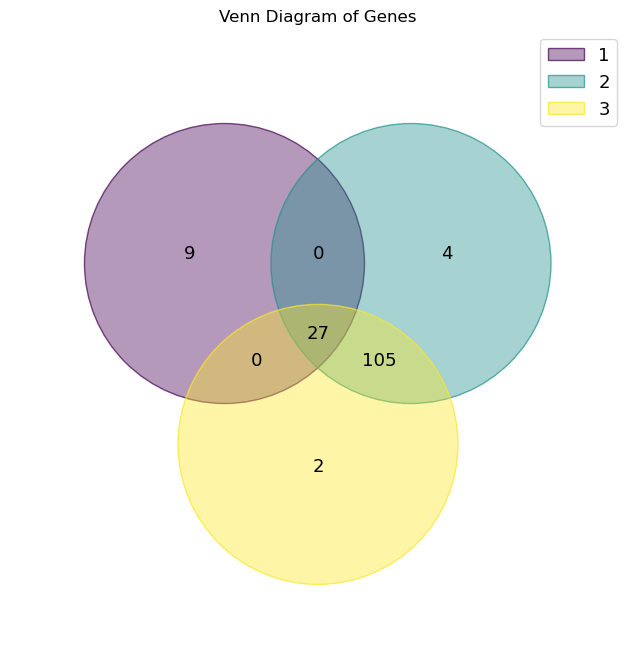

In [183]:
import matplotlib.pyplot as plt
from venn import venn

# 获取每个 DataFrame 中的基因集合
genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

# 绘制 Venn 图
plt.figure(figsize=(8, 8))
venn({1: genes_1, 2: genes_2, 3: genes_3})

# 添加标题
plt.title("Venn Diagram of Genes")

# 显示图形
plt.show()

In [184]:
# 获取每个 DataFrame 中的基因集合
genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

# 计算三个集合的交集
common_genes = genes_1 & genes_2 & genes_3

# 将交集的基因转换为列表并输出
common_genes_list = list(common_genes)

# 查看交集基因列表
print(common_genes_list)


['Met', 'Popdc3', 'Lmo1', 'Blank-13', 'Fstl5', 'Adgrv1', 'Kcng2', 'Npy2r', 'Nr2f1', 'C1ql1', 'Rwdd2a', 'Nts', 'Eomes', 'Cidea', 'Stac', 'Adamtsl1', 'Blank-33', 'Ust', 'Rgs4', 'Gpr101', 'Ndst4', 'G630016G05Rik', 'Trpc7', 'Rorb', 'Tent5a', 'Dsg2', 'Svep1']


In [191]:
import gseapy as gp

# 假设有一个较大的基因集 gene_list
gene_list = common_genes_list

# 进行 GSEA 富集分析（例如：KEGG、GO）
enrichr = gp.enrichr(gene_list=gene_list, gene_sets='GO_Biological_Process_2021', outdir='./gsea_results', cutoff=0.1)
enrichr.results.head()

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,positive regulation of transcription by RNA po...,5/908,0.006694,0.086015,0,0,4.799658,24.029860,LMO1;EOMES;NR2F1;RORB;MET
1,GO_Biological_Process_2021,regulation of guanyl-nucleotide exchange facto...,1/5,0.006732,0.086015,0,0,192.009615,960.206502,MET
2,GO_Biological_Process_2021,amacrine cell differentiation (GO:0035881),1/5,0.006732,0.086015,0,0,192.009615,960.206502,RORB
3,GO_Biological_Process_2021,maintenance of animal organ identity (GO:0048496),1/5,0.006732,0.086015,0,0,192.009615,960.206502,ADGRV1
4,GO_Biological_Process_2021,His-Purkinje system development (GO:0003164),1/5,0.006732,0.086015,0,0,192.009615,960.206502,DSG2


In [169]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_1 = df_deg_A1.join(df_genes, how="left")
############################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_1.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_1[gene], df_merged_1["in_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations = pd.DataFrame(correlations)

df_correlations_sorted = df_correlations.reindex(df_correlations["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted

,gene,r_value,p_value
26,Blank-13,0.383086,0.000211
3,Rgs4,0.368577,0.000379
1,Pitx2,0.361410,0.000502
14,Rspo1,0.299433,0.004363
21,Grik1,-0.273974,0.009376
8,Syndig1,0.265650,0.011866
24,Blank-7,0.264835,0.012139
20,Gpr139,0.256707,0.015167
10,Bmp4,0.252664,0.016902
19,Pde11a,-0.252098,0.017158


In [171]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_2 = df_deg_A2.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_2.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_2[gene], df_merged_2["in_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations2 = pd.DataFrame(correlations)

df_correlations_sorted2 = df_correlations2.reindex(df_correlations2["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted2

,gene,r_value,p_value
77,Blank-13,0.443419,0.000013
5,Rgs4,0.440929,0.000015
41,Clic5,0.386786,0.000181
48,Arhgap15,0.377688,0.000263
30,Bmp4,0.372335,0.000327
...,...,...,...
22,Dlk1,-0.212159,0.045934
25,Baiap3,-0.210979,0.047186
15,Cacng3,0.210493,0.047708
52,Marcksl1,-0.210045,0.048195


In [173]:
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)

df_merged_3 = df_deg_A3.join(df_genes, how="left")
################################################################################
import scipy.stats as stats

correlations = []

for gene in df_merged_3.columns:
    if gene not in ["out_degree_signed", "region", "in_degree_signed"]:
        r_value, p_value = stats.pearsonr(df_merged_3[gene], df_merged_3["in_degree_signed"])
        if p_value < 0.05:
            correlations.append({
                "gene": gene,
                "r_value": r_value,
                "p_value": p_value
            })

df_correlations3 = pd.DataFrame(correlations)

df_correlations_sorted3 = df_correlations3.reindex(df_correlations3["r_value"].abs().sort_values(ascending=False).index)

df_correlations_sorted3

,gene,r_value,p_value
75,Blank-13,0.447765,0.000011
4,Rgs4,0.442583,0.000014
39,Clic5,0.384523,0.000199
46,Arhgap15,0.377289,0.000268
7,Rorb,0.367233,0.000400
...,...,...,...
23,Baiap3,-0.212804,0.045263
5,Gja1,-0.210890,0.047281
24,Cldn5,0.209810,0.048452
0,Igfbp2,0.209538,0.048751


<Figure size 800x800 with 0 Axes>

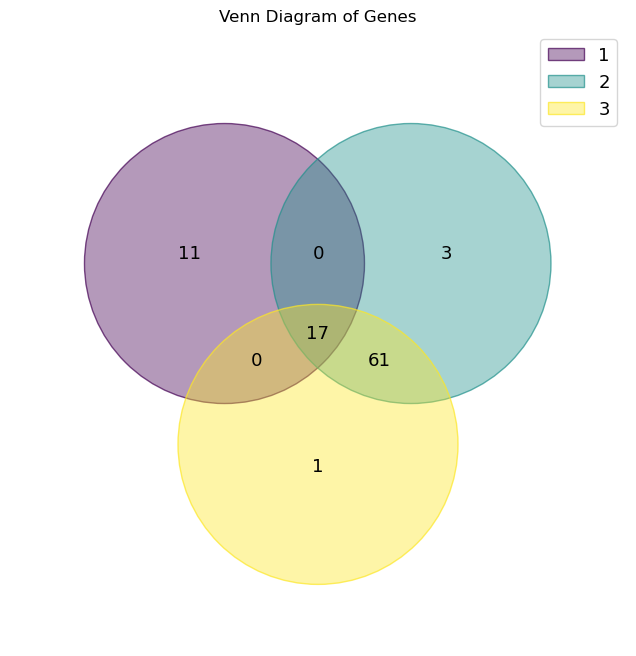

In [174]:
import matplotlib.pyplot as plt
from venn import venn

# 获取每个 DataFrame 中的基因集合
genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

# 绘制 Venn 图
plt.figure(figsize=(8, 8))
venn({1: genes_1, 2: genes_2, 3: genes_3})

# 添加标题
plt.title("Venn Diagram of Genes")

# 显示图形
plt.show()

In [175]:
# 获取每个 DataFrame 中的基因集合
genes_1 = set(df_correlations_sorted["gene"])
genes_2 = set(df_correlations_sorted2["gene"])
genes_3 = set(df_correlations_sorted3["gene"])

# 计算三个集合的交集
common_genes = genes_1 & genes_2 & genes_3

# 将交集的基因转换为列表并输出
common_genes_list = list(common_genes)

# 查看交集基因列表
print(common_genes_list)


['Prom1', 'Grik1', 'Pitx2', 'Syndig1', 'Lamp5', 'Rgs4', 'Blank-32', 'Gpr139', 'Pparg', 'Bmp4', 'Rspo1', 'Plpp4', 'Blank-13', 'Blank-7', 'Rorb', 'Dsg2', 'Grm3']


## WGCNA

/tmp/ipykernel_2693194/3153345821.py:27: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  Z = linkage(distance_matrix, method='average')  # 层次聚类


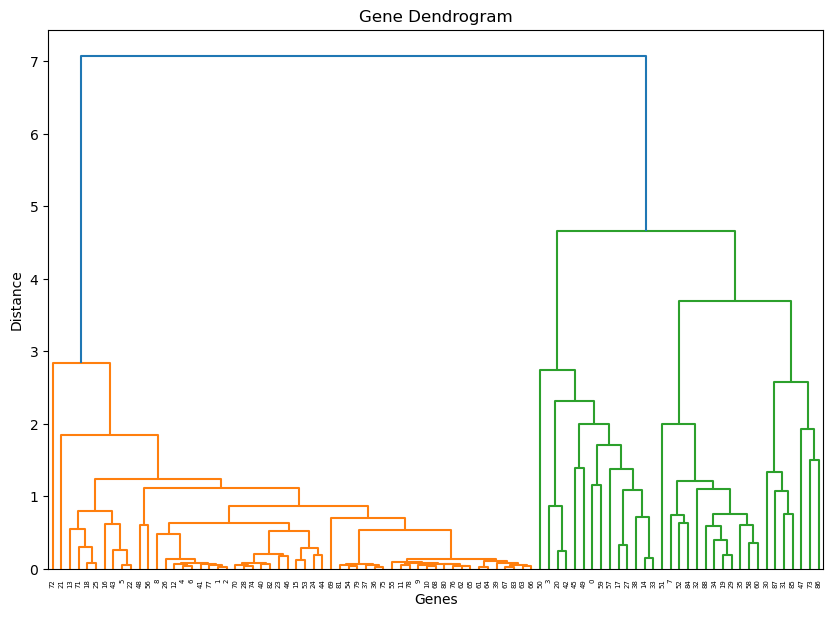

Module 1: Correlation = -0.011, p-value = 0.919
Module 2: Correlation = 0.003, p-value = 0.980
Module 3: Correlation = 0.017, p-value = 0.872
Module 4: Correlation = 0.134, p-value = 0.212


In [176]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster

# 1. 加载基因表达矩阵
df_genes = pd.read_csv("../transcriptome/merfish/merfish_group_by_region.csv")
df_genes.set_index(df_genes.columns[0], inplace=True)  # 假设第一列是脑区，作为index

# 2. 转置数据：让基因成为行，脑区成为列
df_genes_transposed = df_genes.T

# 3. 数据标准化：对基因表达数据进行标准化
df_genes_transposed_normalized = (df_genes_transposed - df_genes_transposed.mean()) / df_genes_transposed.std()

# 4. 计算基因之间的相关性（Pearson 相关系数）
correlation_matrix = np.corrcoef(df_genes_transposed_normalized, rowvar=False)

# 5. 转换为加权网络：可以设置一个阈值，低相关性值变为0
threshold = 0.5  # 设置一个阈值，去除低相关性基因
adjacency_matrix = np.where(correlation_matrix > threshold, correlation_matrix, 0)

# 6. 模块检测：使用层次聚类来识别基因模块
distance_matrix = 1 - adjacency_matrix  # 距离矩阵是1-相关性
Z = linkage(distance_matrix, method='average')  # 层次聚类

# 绘制聚类树（dendrogram）
plt.figure(figsize=(10, 7))
dendrogram(Z)
plt.title('Gene Dendrogram')
plt.xlabel('Genes')
plt.ylabel('Distance')
plt.show()

# 7. 模块分配：设置一个合适的阈值，分割为多个模块
modules = fcluster(Z, t=4, criterion='maxclust')  # 假设分成4个模块

# 8. 模块与外部表型的关联
# 假设我们有一个脑区信息
brain_region = np.random.randint(1, 4, size=df_genes_transposed.shape[1])  # 假设有3个脑区

# 计算每个模块与脑区的相关性
module_trait_correlations = []
for module in np.unique(modules):
    module_genes = np.where(modules == module)[0]
    module_expression = np.mean(df_genes_transposed_normalized.iloc[module_genes], axis=0)  # 计算模块基因的平均表达
    corr, p_value = stats.pearsonr(module_expression, brain_region)  # 计算与脑区的相关性
    module_trait_correlations.append((module, corr, p_value))

# 输出结果
for module, corr, p_value in module_trait_correlations:
    print(f"Module {module}: Correlation = {corr:.3f}, p-value = {p_value:.3f}")
